### IPD441 - Visión por Computador
# Clase 5: Circuits 
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Black-box

Las redes neuronales, aunque pueden producir resultados precisos, el proceso interno mediante el cual llegan a esas conclusiones puede no ser fácilmente comprensible o interpretable para los humanos.

<div align="center">
    <img src="img/black-box.jpg" alt="" width="50%" align="center" />
</div>

# Zoom-in

Muchos puntos de transición importantes en la historia de la ciencia han sido momentos en los que la ciencia hizo un “zoom-in”.

<div align="center">
    <img src="img/zoom-in-black-box.png" alt="" width="50%" align="center" />
</div>

# Tres afirmaciones especulativas sobre las redes neuronales

1. **Features:** Las características son la unidad fundamental de las redes neuronales. Corresponden a direcciones. Estas características pueden estudiarse y comprenderse rigurosamente.

2. **Circuitos:** Las características están conectadas por pesos, formando circuitos. Estos circuitos también pueden estudiarse y comprenderse rigurosamente.
 
3. **Universalidad:** Se forman características y circuitos análogos en todos los modelos y tareas.

# Features

<div align="right">
    <img src="img/features.png" alt="" width="30%" align="right" />
</div>

Representaciones abstractas de los datos de entrada que la red aprende a identificar y extraer durante su entrenamiento.

Generalmente, se cree que las primeras capas aprenden características simples como curvas o bordes, y las capas más profundas se especializan en representaciones más complejas.



In [1]:
# pip install torch-lucent

In [2]:
# pip install torch-dreams

In [3]:
from lucent.modelzoo import inceptionv1

In [4]:
from lucent.misc.io import show

In [5]:
import torch

from lucent.optvis import render, param, transform, objectives
from lucent.modelzoo.util import get_model_layers

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [6]:
import matplotlib.pyplot as plt
import torchvision.models as models
from torch_dreams import Dreamer

In [33]:
def feature_visualization(model, layers, param_f=None, optimizer=None, labels=None):
    for lay in layers:
        list_of_images = []
        neurons = layers[lay]
        for n in neurons:
            objective_f = lay + ":" + str(n)
            list_of_images.append(render.render_vis(model, 
                                                    objective_f, 
                                                    param_f=param_f, 
                                                    optimizer=optimizer, 
                                                    show_inline=False, 
                                                    show_image=False, 
                                                    progress=False))
        print(lay)
        show(list_of_images, labels=labels)

## Feature Visualization

Cómo las redes neuronales desarrollan su comprensión de las imágenes.

<div align="center">
    <img src="img/GoogleNet.png" alt="" width="100%" align="center" />
</div>

In [8]:
inceptionv1_model = inceptionv1(pretrained=True)
_ = inceptionv1_model.to(device).eval()

In [9]:
print(get_model_layers(inceptionv1_model))

['conv2d0_pre_relu_conv', 'conv2d1_pre_relu_conv', 'conv2d2_pre_relu_conv', 'mixed3a_1x1_pre_relu_conv', 'mixed3a_3x3_bottleneck_pre_relu_conv', 'mixed3a_5x5_bottleneck_pre_relu_conv', 'mixed3a_pool_reduce_pre_relu_conv', 'mixed3a_3x3_pre_relu_conv', 'mixed3a_5x5_pre_relu_conv', 'mixed3b_1x1_pre_relu_conv', 'mixed3b_3x3_bottleneck_pre_relu_conv', 'mixed3b_5x5_bottleneck_pre_relu_conv', 'mixed3b_pool_reduce_pre_relu_conv', 'mixed3b_3x3_pre_relu_conv', 'mixed3b_5x5_pre_relu_conv', 'mixed4a_1x1_pre_relu_conv', 'mixed4a_3x3_bottleneck_pre_relu_conv', 'mixed4a_5x5_bottleneck_pre_relu_conv', 'mixed4a_pool_reduce_pre_relu_conv', 'mixed4a_3x3_pre_relu_conv', 'mixed4a_5x5_pre_relu_conv', 'mixed4b_1x1_pre_relu_conv', 'mixed4b_3x3_bottleneck_pre_relu_conv', 'mixed4b_5x5_bottleneck_pre_relu_conv', 'mixed4b_pool_reduce_pre_relu_conv', 'mixed4b_3x3_pre_relu_conv', 'mixed4b_5x5_pre_relu_conv', 'mixed4c_1x1_pre_relu_conv', 'mixed4c_3x3_bottleneck_pre_relu_conv', 'mixed4c_5x5_bottleneck_pre_relu_conv',

## Low-level Visual Features

Curve Detectors

mixed3b



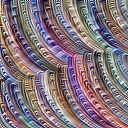
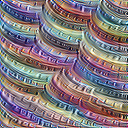
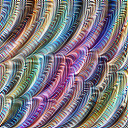
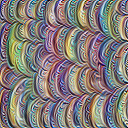
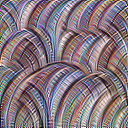
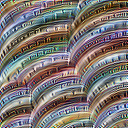
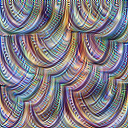
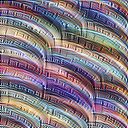
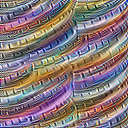

In [10]:
feature_visualization(inceptionv1_model, {"mixed3b": [330,340,342,349,359,379,380,385,388]})

## High-level Visual Features

mixed5b



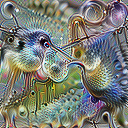
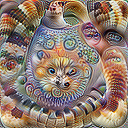
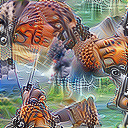
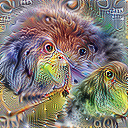
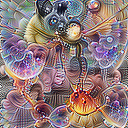
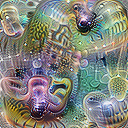
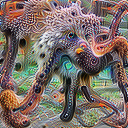
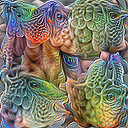
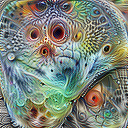

In [151]:
feature_visualization(inceptionv1_model, {"mixed5b": [46,52,115,165,340,361,364,368,397]})

In [113]:
layers = {
    "conv2d0" : [0,1,2,3,4,5],
    "mixed3a" : [39, 43, 61, 68, 230, 239], 
    "mixed4a" : [0, 27, 492, 500, 501, 502], 
    "mixed4e" : [167, 555, 604, 662, 809, 815] }

conv2d0



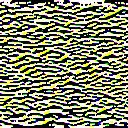
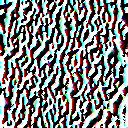
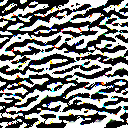
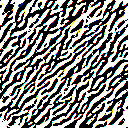
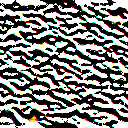
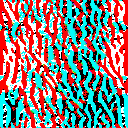

mixed3a



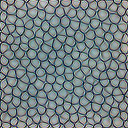
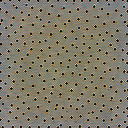
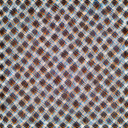
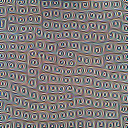
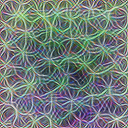
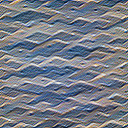

mixed4a



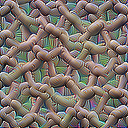
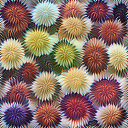
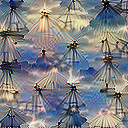
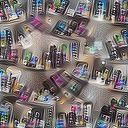
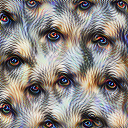
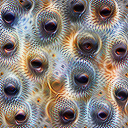

mixed4e



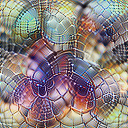
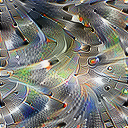
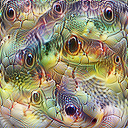
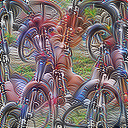
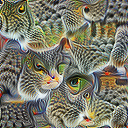
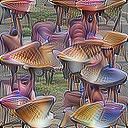

In [114]:
feature_visualization(inceptionv1_model, layers)

## Feature Visualization by Optimization

Las redes neuronales son en general diferenciables con respecto a sus entradas. Si queremos saber que tipo de entrada causa determinado comportamiento, podemos derivar iterativamente la entrada hacia un objetivo. A partir de ruido aleatorio, optimizamos una imagen para activar una neurona particular (capa mixed4a, unidad 11).

In [130]:
def feature_optimization(model, objective_f, steps):
    list_of_images = []
    for step in steps:
        list_of_images.append(render.render_vis(model, objective_f, 
                                                show_inline=False, 
                                                show_image=False, 
                                                thresholds=(step,),
                                                progress=False))
    show(list_of_images)


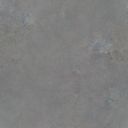
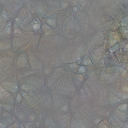
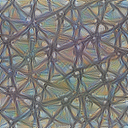
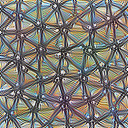
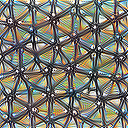

In [136]:
feature_optimization(inceptionv1_model, "mixed4a:11", steps=[1, 4, 48, 512, 2048])

## Optimization Objectives

Los diferentes objetivos de optimización muestran lo que buscan las diferentes partes de una red.

<div align="center">
    <img src="img/Optimization_Objectives.png" alt="" width="60%" align="center" />
</div>

## ¿Por qué visualizar mediante optimización?

La optimización puede darnos un ejemplo de entrada que causa un comportamiento deseado porque aísla las causas del comportamiento de las meras correlaciones. Puede que una neurona no esté detectando lo que pensabas inicialmente. Por ejemplo, considere los siguientes datos y veamos que neuronas responden a ellos.

<div align="center">
    <img src="img/opti_examples.png" alt="" width="100%" align="center" />
</div>

mixed4a



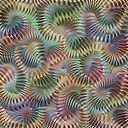
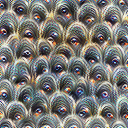
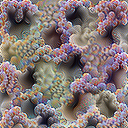
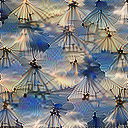

In [139]:
feature_visualization(inceptionv1_model, {"mixed4a" : [6,240,453,492] })

## Diversity

Cuando creamos ejemplos mediante optimización, es muy posible que los ejemplos genuinos aún nos engañen al mostrarnos solo una "faceta" de lo que representa una característica.

### Negative Channel Visualizations

La optimización nos da sólo un ejemplo extremadamente positivo, pero también podemos generar visualizaciones que maximicen las activaciones en la dirección opuesta (negativa).

In [10]:
param_f = lambda: param.image(224, batch=2)


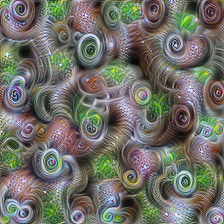
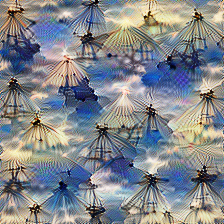

In [11]:
obj = objectives.channel("mixed4a", 492, batch=1) - objectives.channel("mixed4a", 492, batch=0)
_ = render.render_vis(inceptionv1_model, obj, param_f, show_inline=True, progress=False)


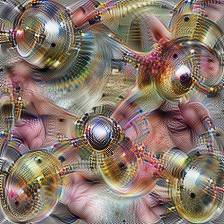
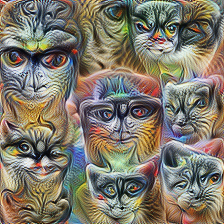

In [12]:
param_f = lambda: param.image(224, batch=2)
obj = objectives.channel("mixed4e", 819, batch=1) - objectives.channel("mixed4e", 819, batch=0)
_ = render.render_vis(inceptionv1_model, obj, param_f, show_inline=True, progress=False)

### Achieving Diversity with Optimization

Con el objetivo de diversidad, tenemos que enviar un lote de imágenes para su optimización. Luego, el objetivo de diversidad intenta maximizar la diferencia en las representaciones de características entre las imágenes del lote. 

Específicamente, el objetivo penaliza la similitud del coseno entre las representaciones de características.

In [13]:
batch_param_f = lambda: param.image(128, batch=4)

#### Optimization with diversity reveals four different, curvy facets. Layer mixed4a, Unit 97

En las neuronas de nivel inferior, un término de diversidad puede revelar las diferentes facetas que representa una característica:


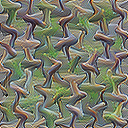
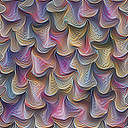
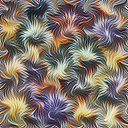
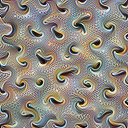

In [14]:
obj = objectives.channel("mixed4a", 97) - 1e3 * objectives.diversity("mixed4a")
_ = render.render_vis(inceptionv1_model, obj, batch_param_f, show_inline=True, progress=False)

#### Optimization with diversity. Layer mixed4a, Unit 143

<div align="right">
    <img src="img/mixed4a_143.png" alt="" width="30%" align="right" />
</div>

Mirándolo de forma aislada se podría inferir que esta neurona se activa en la parte superior de las cabezas de los perros. Sin embargo, al observar la optimización con diversidad, vemos resultados de optimización que no incluyen ojos y también uno que incluye bordes curvos hacia arriba. Por lo tanto, podríamos concluir que hace referencia a la textura del pelaje.



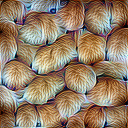
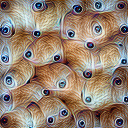
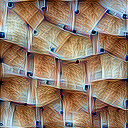
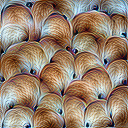

In [15]:
obj = objectives.channel("mixed4a", 143) - 1e2 * objectives.diversity("mixed4a")
_ = render.render_vis(inceptionv1_model, obj, batch_param_f, show_inline=True, progress=False)

## Polysemantic Neurons

<div align="right">
    <img src="img/mixed4e_55.jpeg" alt="" width="15%" align="right" />
</div>

Si bien los ejemplos anteriores representan una idea mayoritariamente coherente, también hay neuronas que representan extrañas mezclas de ideas. Abajo, una neurona responde a dos tipos de caras de animales y también a carrocerías de automóviles.

In [16]:
batch_param_f = lambda: param.image(128, batch=4)


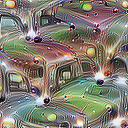
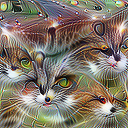
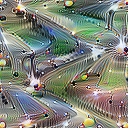
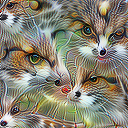

In [17]:
obj = objectives.channel("mixed4e", 55) - 1e2 * objectives.diversity("mixed4e")
_ = render.render_vis(inceptionv1_model, obj, batch_param_f, show_inline=True, progress=False)

# Circuits

Son conexiones que forman las características a través de los pesos.

<div align="center">
    <img src="img/Neural_Circuit.jpeg" alt="" width="20%" align="center" />
</div>

## Interaction between Neurons

En la vida real, combinaciones de neuronas trabajan juntas para representar imágenes en el cerebro. 

<div align="center">
    <img src="img/sinapsis.png" alt="" width="50%" align="center" />
</div>

Las neuronas artificiales se pueden entender geométricamente como vectores en un espacio de activación neuronal. ¿Qué indica la dirección de estos vectores?

## Combining Neurons

Podemos definir direcciones interesantes en el espacio de activación haciendo aritmética con las neuronas. Por ejemplo, si sumamos una neurona “blanco y negro” a una neurona “mosaico”, obtenemos una versión en blanco y negro del mosaico. Esto recuerda a la aritmética semántica de los word embeddings (Word2Vec) o en los espacios latentes de los modelos generativos.

In [18]:
# ('mixed4b', 111)   # large fluffy
# ('mixed3a', 139)   # pointilist
# ('mixed3b',  81)   # brush trokes
# ('mixed4a',  97)   # wavy
# ('mixed4a',  41)   # frames
# ('mixed4a', 479)   # B/W
# ('mixed4a', 476)   # art
# ('mixed4b', 360)   # lattices
# ('mixed4b', 482)   # arcs
# ('mixed4c', 440)   # small fluffy
# ('mixed4d', 479)   # bird beaks
# ('mixed4e', 718)   # shoulders

In [19]:
neuron1 = ('mixed4a', 479)   # B/W
neuron2 = ('mixed4a', 476)   # art
neuron3 = ('mixed4b', 111)   # large fluffy

In [20]:
param_f = lambda: param.image(128, batch=3)

In [21]:
# First image optimizes neuron1
# Second image optimizes neuron2
# Third image optimizes sum of both
C = lambda neuron1, neuron2: objectives.channel(*neuron1, batch=0) + \
  objectives.channel(*neuron2, batch=1) + \
  objectives.channel(*neuron1, batch=2) + \
  objectives.channel(*neuron2, batch=2)


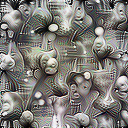
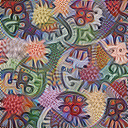
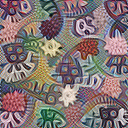

In [215]:
_ = render.render_vis(inceptionv1_model, C(neuron1, neuron2), param_f, show_inline=True, progress=False)


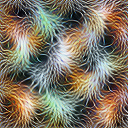
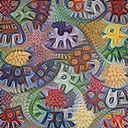
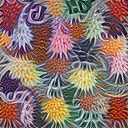

In [216]:
_ = render.render_vis(inceptionv1_model, C(neuron3, neuron2), param_f, show_inline=True, progress=False)

### Aligned Interpolation 

Estos ejemplos nos muestran cómo las neuronas representan imágenes de forma conjunta. Para comprender mejor cómo interactúan las neuronas, también podemos interpolar entre ellas. Esto es similar a interpolar en el espacio latente de modelos generativos.

In [22]:
def interpolate_param_f():
    # We start with a batch of FFT parameterized images
    params, image_f = param.fft_image((6, 3, 128, 128))
    # We then add a bunch of low-res interpolated tensors
    shared = [
      param.lowres_tensor((6, 3, 128, 128), (1, 3, 128//2, 128//2)),
      param.lowres_tensor((6, 3, 128, 128), (1, 3, 128//4, 128//4)),
      param.lowres_tensor((6, 3, 128, 128), (1, 3, 128//8, 128//8)),
      param.lowres_tensor((6, 3, 128, 128), (2, 3, 128//8, 128//8)),
      param.lowres_tensor((6, 3, 128, 128), (1, 3, 128//16, 128//16)),
      param.lowres_tensor((6, 3, 128, 128), (2, 3, 128//16, 128//16)),
    ]
    # Accumulate the params and outputs
    images = []
    for (p, i) in shared:
        params += p
        images.append(i)
    return params, param.to_valid_rgb(lambda: image_f() + sum([i() for i in images]), decorrelate=True)


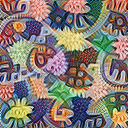
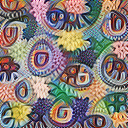
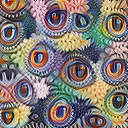
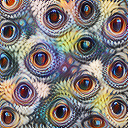
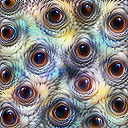
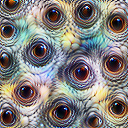

In [206]:
obj = objectives.channel_interpolate("mixed4a", 476, "mixed4a", 460)
seq_1 = render.render_vis(inceptionv1_model, obj, interpolate_param_f, show_inline=True, progress=False)


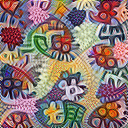
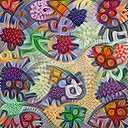
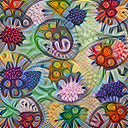
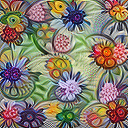
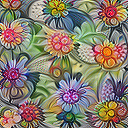
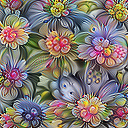

In [208]:
obj = objectives.channel_interpolate("mixed4a", 476, "mixed4d_3x3_bottleneck_pre_relu_conv", 139)
seq_2 = render.render_vis(inceptionv1_model, obj, interpolate_param_f, show_inline=True, progress=False)

### Circuit: Cars in Superposition

En mixed4c, una capa intermedia de InceptionV1, hay una neurona (447) de detección de automóviles.


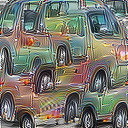

In [174]:
_ = render.render_vis(inceptionv1_model, "mixed4c:447", show_inline=True, progress=False)

### Circuits: mixed4b
<div align="right">
    <img src="img/car_superposition.png" alt="" width="40%" align="right" />
</div>
Utilizando características de la capa anterior (mixed4b), busca ruedas en la parte inferior de su filtro convolucional y ventanas en la parte superior.



mixed4b



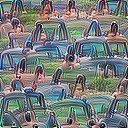
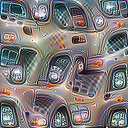
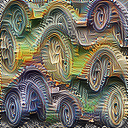

In [169]:
feature_visualization(inceptionv1_model, {"mixed4b" : [237,491,373]})

### Circuits: mixed4d
<div align="right">
    <img src="img/polysemantic.png" alt="" width="35%" align="right" />
</div>
Pero entonces el modelo hace algo sorprendente. En lugar de crear otro detector de automóviles puro en la siguiente capa, extiende su función de automóvil a una serie de neuronas que parecen estar haciendo principalmente otra cosa (detectando perros?).

mixed4d



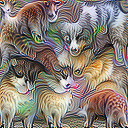
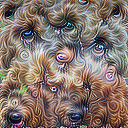
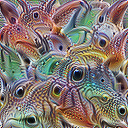

In [170]:
feature_visualization(inceptionv1_model, {"mixed4d" : [417,241,277]})

### Optimizing output channels

Al igual como previamente se optimizaron las primeras capas y luego capas intermedias, es posible optimizar canales de salida que hacen referencia a las clases de un modelo de clasificación. Por ejemplo, el modelo de segmentación DeepLabV3:

In [23]:
segmentation_model = models.segmentation.deeplabv3_resnet50(pretrained=True).eval()

In [24]:
list(dict(segmentation_model.backbone.named_children()).keys())

['conv1', 'bn1', 'relu', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4']

In [25]:
classes = ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike',
 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']

In [26]:
dreamy_boi = Dreamer(segmentation_model, quiet = False, device = 'cpu')
layers_to_use = [
    segmentation_model.aux_classifier[-1]
]

In [ ]:
all_outs = []
for i in range(21):
    my_func = make_custom_func(layer_number=0, channel_number= i)
    image_param = dreamy_boi.render(
        width = 256,
        height = 256,
        iters = 190,
        layers = layers_to_use,
        custom_func= my_func,
        lr = 8e-3,
        rotate_degrees = 25,
        scale_max= 1.2,
        scale_min= 0.2
    )
    all_outs.append(image_param)

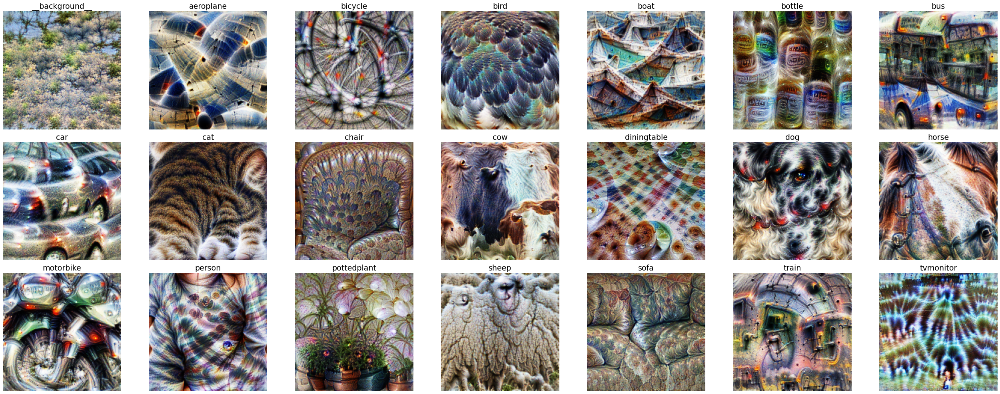

In [36]:
fig, ax = plt.subplots(nrows= 3, ncols= len(classes)//3, figsize=(18*2, 6*2.3))
for i in range(len(all_outs)):
    ax.flat[i].imshow(all_outs[i])
    ax.flat[i].set_title(classes[i], fontsize = 19)
    ax.flat[i].axis("off")
fig.tight_layout()

# Universality

Ya se ha sugerido antes la universalidad (o “aprendizaje convergente”) de las características. Se ha demostrado que diferentes redes neuronales pueden desarrollar neuronas altamente correlacionadas y que aprenden representaciones similares en capas ocultas.

In [27]:
from torchvision.models import resnet50, googlenet, vgg19, alexnet
from lucent.modelzoo import mobilenet_v2

In [28]:
vgg19_model = vgg19(pretrained=True).to(device).eval()
alexnet_model = alexnet(pretrained=True).to(device).eval()
resnet50_model = resnet50(pretrained=True).to(device).eval()
googlenet_model = googlenet(pretrained=True).to(device).eval()
mobilenet_v2_model = mobilenet_v2(pretrained=True).to(device).eval()

In [29]:
low_level = {
    "vgg19_model":{"features_1":[0,3,46]},
    "alexnet_model":{"features_1":[1,6,8]},
    "resnet50_model":{"layer1_0_conv1":[1,2,8]},
    "googlenet_model":{"conv2":[1,3,7]},
}

In [197]:
def vis_models(layers):
    print("vgg19_model")
    feature_visualization(vgg19_model, layers["vgg19_model"])
    print("alexnet_model")
    feature_visualization(alexnet_model, layers["alexnet_model"])
    print("resnet50_model")
    feature_visualization(resnet50_model, layers["resnet50_model"])
    print("googlenet_model")
    feature_visualization(googlenet_model, layers["googlenet_model"])

vgg19_model
features_1



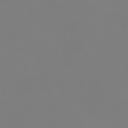
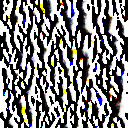
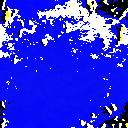

alexnet_model
features_1



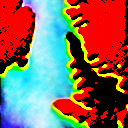
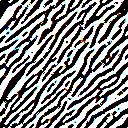
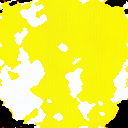

resnet50_model
layer1_0_conv1



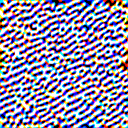
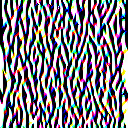
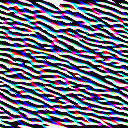

googlenet_model
conv2



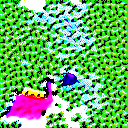
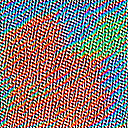
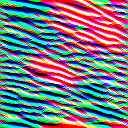

In [198]:
vis_models(low_level)

In [30]:
labels = {"labels":[340,543,949]}
names = ["zebra","dumbbell","strawberry"]

In [31]:
def vis_labels_models(layers, names):
    cppn_param_f = lambda: param.cppn(224)
    cppn_opt = lambda params: torch.optim.Adam(params, 5e-3)
    print("alexnet_model")
    feature_visualization(alexnet_model, layers, cppn_param_f, cppn_opt, labels=names)
    print("vgg19_model")
    feature_visualization(vgg19_model, layers, cppn_param_f, cppn_opt, labels=names)
    print("resnet50_model")
    feature_visualization(resnet50_model, layers, cppn_param_f, cppn_opt, labels=names)
    print("googlenet_model")
    feature_visualization(googlenet_model, layers, cppn_param_f, cppn_opt, labels=names)
    print("mobilenet_v2_model")
    feature_visualization(mobilenet_v2_model, layers, cppn_param_f, cppn_opt, labels=names)

alexnet_model
labels



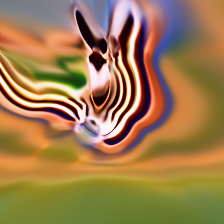
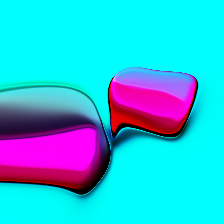
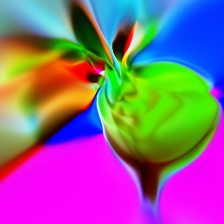

vgg19_model
labels



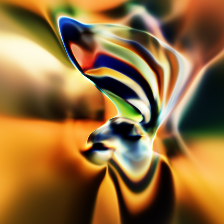
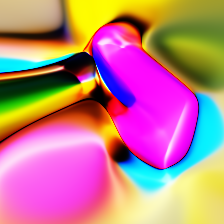
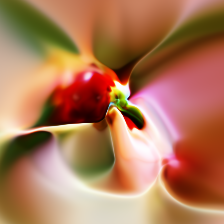

resnet50_model
labels



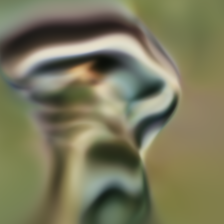
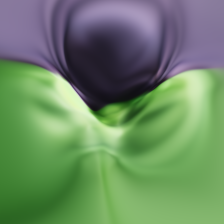
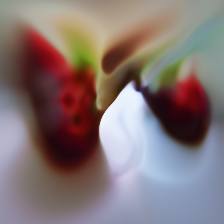

googlenet_model
labels



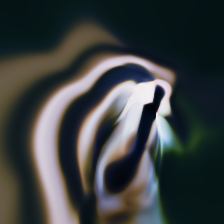
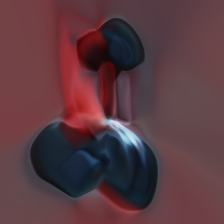
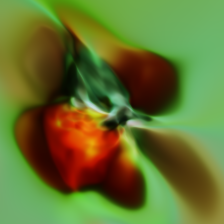

mobilenet_v2_model
labels



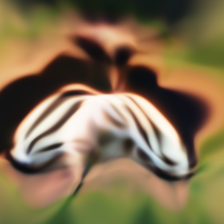
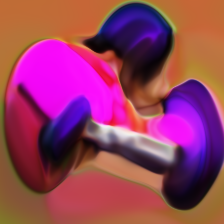
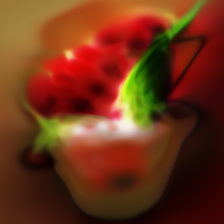

In [34]:
vis_labels_models(labels,names)